# Notebook 18 — Final Scientific Figures: CHIRPS v2, v3, Atmospheric Features & Terrain

**Scientific purpose:** visualize the research conclusions without using the test period for model selection. This notebook reads your original datasets, reproduces the fixed Notebook 17 station-specific Ridge comparison, and produces publication-style figures and CSV tables for your report.

**Design:** train 1981–1990, validation/model selection 1991–1994, historical test 1995–2000. The supplied terrain-gradient file is the **earlier/exploratory** version, so do not claim this verifies corrected orographic forcing. Correlation is not causation. Six stations are only six independent spatial units.

**Figures:** (1) Daily product RMSE; (2) daily product correlation; (3) model comparison; (4) wet-day and heavy-rainfall tradeoffs; (5) Pearson and Spearman atmospheric heatmaps; (6) station-specific Kandy/Nuwara Eliya/Colombo correlations; (7) terrain vs error scatter; (8) monthly climatology; (9) normalized cumulative rainfall; (10) daily scatter plots; (11) optional buffered spatial/temporal plots if 40 annual CSV files exist.


## 1 — Imports and directories
Place this notebook in `Sri Lanka Rainfall Research/notebooks/`. Input CSV-text `.xls` files also work. New unique `results/18_Final_Visualizations/run_###/` folder, never overwrite earlier results.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from IPython.display import display

plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':220, 'axes.grid':True,
                     'grid.alpha':0.18, 'font.size':10})
HERE=Path.cwd().resolve()
ROOT=next((p for p in (HERE,HERE.parent) if (p/'data'/'processed').exists()),
          HERE.parent if HERE.name.lower()=='notebooks' else HERE)
DATA_DIR=ROOT/'data'/'processed'
BUFFER_DIR=ROOT/'data'/'chirps'/'buffered'
BASE_OUT=ROOT/'results'/'18_Final_Visualizations'
BASE_OUT.mkdir(parents=True,exist_ok=True)
run_id=1
while (BASE_OUT/f'run_{run_id:03d}').exists():run_id+=1
OUT=BASE_OUT/f'run_{run_id:03d}'
OUT.mkdir(exist_ok=False)

def find_csv(stem):
    for base in (DATA_DIR,ROOT,Path('/mnt/data')):
        for ext in ('.csv','.xls'):
            f=base/(stem+ext)
            if f.exists():return f
    raise FileNotFoundError(f'{stem}.csv not found. Put it in {DATA_DIR}')

def savefig(name):
    plt.savefig(OUT/(name+'.png'),bbox_inches='tight',dpi=220)
    plt.savefig(OUT/(name+'.pdf'),bbox_inches='tight')
    plt.show()
print('Inputs:',DATA_DIR)
print('Output (new only):',OUT)


Inputs: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed
Output (new only): C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\18_Final_Visualizations\run_001


## 2 — Load and check paired observations (use identical valid dates)

In [3]:
a=pd.read_csv(find_csv('Ground_CHIRPS_ERA5_Terrain_1981_2000'),parse_dates=['Date'])
g=pd.read_csv(find_csv('Ground_CHIRPS_V2_V3_Paired_1981_2000'),parse_dates=['Date'])
for d in (a,g):
    d['Station']=d.Station.astype(str).str.strip().replace({'Nuwara Eliya':'Nuwaraeliya'})
    assert not d.duplicated(['Station','Date']).any(),'Duplicate station-date row'
vars_check=['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']
verified=a[['Station','Date']+vars_check].merge(g[['Station','Date']+vars_check],
    on=['Station','Date'],how='outer',indicator=True,validate='one_to_one',suffixes=('_atmos','_paired'))
assert verified._merge.eq('both').all(),'Input datasets cover different dates'
for variable in vars_check:
    assert np.allclose(verified[variable+'_atmos'],verified[variable+'_paired'],equal_nan=True),f'{variable} mismatch'
needed=vars_check+['Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms',
                    'Orographic_Index','Upslope_w_ms']
assert not set(needed)-set(a), 'Missing model features: '+str(set(needed)-set(a))
df=a.copy()
for col in needed:df[col]=pd.to_numeric(df[col],errors='coerce')
df=df.dropna(subset=needed).copy()
df=df.loc[(df.Rainfall_mm>=0)&(df.CHIRPS_mm>=0)&(df.CHIRPS_V3_mm>=0)].copy()
df=df.sort_values(['Station','Date']).reset_index(drop=True)
df['Station_label']=df.Station.replace({'Nuwaraeliya':'Nuwara Eliya'})
train=df.loc[df.Date.between('1981-01-01','1990-12-31')].copy()
valid=df.loc[df.Date.between('1991-01-01','1994-12-31')].copy()
test=df.loc[df.Date.between('1995-01-01','2000-12-31')].copy()
stations=sorted(df.Station.unique())
assert len(test)>0 and len(train)>0 and len(valid)>0
print('Matched records:',len(df),'Test rows:',len(test),'Stations:',stations)
display(df.groupby('Station_label').agg(Days=('Date','size'),Start=('Date','min'),End=('Date','max')))


C:\Users\Asini Perera\AppData\Local\Temp\ipykernel_28412\1074467188.py:1: DtypeWarning: Columns (2: Original_Value) have mixed types. Specify dtype option on import or set low_memory=False.
  a=pd.read_csv(find_csv('Ground_CHIRPS_ERA5_Terrain_1981_2000'),parse_dates=['Date'])


Matched records: 43737 Test rows: 13134 Stations: ['Badulla', 'Colombo', 'Galle', 'Kandy', 'Nuwaraeliya', 'Puttalam']


,Days,Start,End
Station_label,,,
Badulla,7300,1981-01-01,2000-12-31
Colombo,7279,1981-01-01,2000-12-31
Galle,7291,1981-01-01,2000-12-31
Kandy,7296,1981-01-01,2000-12-31
Nuwara Eliya,7278,1981-01-01,2000-12-31
Puttalam,7293,1981-01-01,2000-12-31


## 3 — Statistics used consistently across all figures

Signed bias is prediction minus observed; wet day is rainfall ≥1 mm/day and heavy event is **observed gauge >25 mm/day**. Metrics on complete months use all calendar days (no zero filling).

In [5]:
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float)
    e=p-y
    if len(y)==0:return {'N':0,'Bias':np.nan,'MAE':np.nan,'RMSE':np.nan,'Pearson_r':np.nan,'Spearman_r':np.nan}
    hasvar=len(y)>2 and np.std(y)>0 and np.std(p)>0
    return dict(N=len(y),Bias=float(e.mean()),MAE=float(np.abs(e).mean()),
       RMSE=float(np.sqrt(np.mean(e**2))),
       Pearson_r=float(np.corrcoef(y,p)[0,1]) if hasvar else np.nan,
       Spearman_r=float(spearmanr(y,p).statistic) if hasvar else np.nan)

def wet(y,p,t=1.0):
    obs=np.asarray(y)>=t;pred=np.asarray(p)>=t
    H=int((obs&pred).sum());M=int((obs&~pred).sum());F=int((~obs&pred).sum())
    C=int((~obs&~pred).sum())
    div=lambda x,d:x/d if d else np.nan
    return dict(H=H,M=M,F=F,C=C,POD=div(H,H+M),FAR=div(F,H+F),CSI=div(H,H+M+F))

rows=[]; event=[];heavy=[]
for st,t in test.groupby('Station'):
    for version,col in [('v2','CHIRPS_mm'),('v3 RNL','CHIRPS_V3_mm')]:
        rows.append(dict(Station=st,Version=version,**metrics(t.Rainfall_mm,t[col])))
        event.append(dict(Station=st,Version=version,**wet(t.Rainfall_mm,t[col])))
        h=t[t.Rainfall_mm>25]
        heavy.append(dict(Station=st,Version=version,**metrics(h.Rainfall_mm,h[col])))
product_scores=pd.DataFrame(rows)
product_wet=pd.DataFrame(event)
product_heavy=pd.DataFrame(heavy)
display(product_scores.round(3))


,Station,Version,N,Bias,MAE,RMSE,Pearson_r,Spearman_r
0,Badulla,v2,2191,0.589,5.531,11.297,0.387,0.443
1,Badulla,v3 RNL,2191,0.465,4.938,10.189,0.456,0.550
2,Colombo,v2,2191,-0.386,7.539,16.207,0.369,0.468
3,Colombo,v3 RNL,2191,0.483,7.203,14.543,0.503,0.562
4,Galle,v2,2192,-0.688,7.241,15.223,0.433,0.398
5,Galle,v3 RNL,2192,-0.070,6.774,13.747,0.482,0.531
6,Kandy,v2,2190,0.711,6.487,12.776,0.334,0.394
7,Kandy,v3 RNL,2190,0.180,5.361,10.829,0.433,0.531
8,Nuwaraeliya,v2,2180,1.065,7.056,12.937,0.357,0.392
9,Nuwaraeliya,v3 RNL,2180,-0.145,5.490,10.261,0.426,0.568


## 4 — CHIRPS v2 versus v3: daily RMSE and correlation

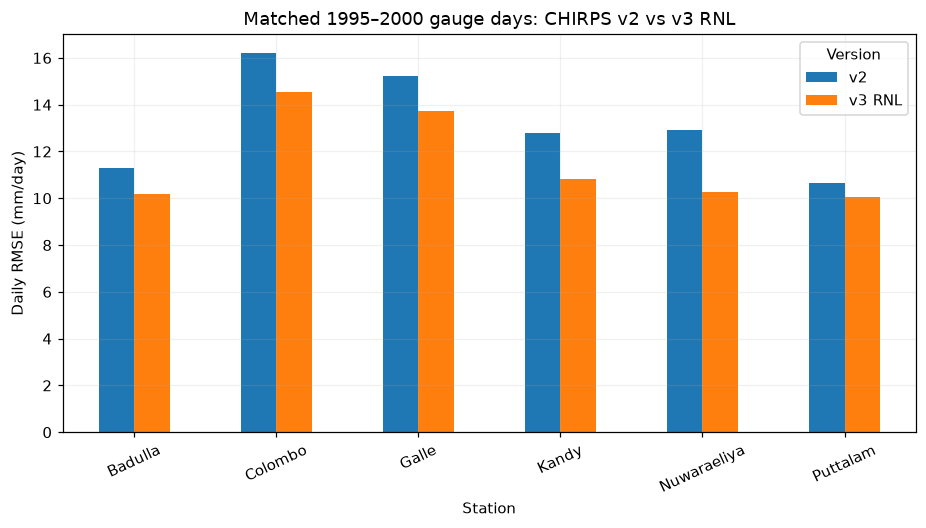

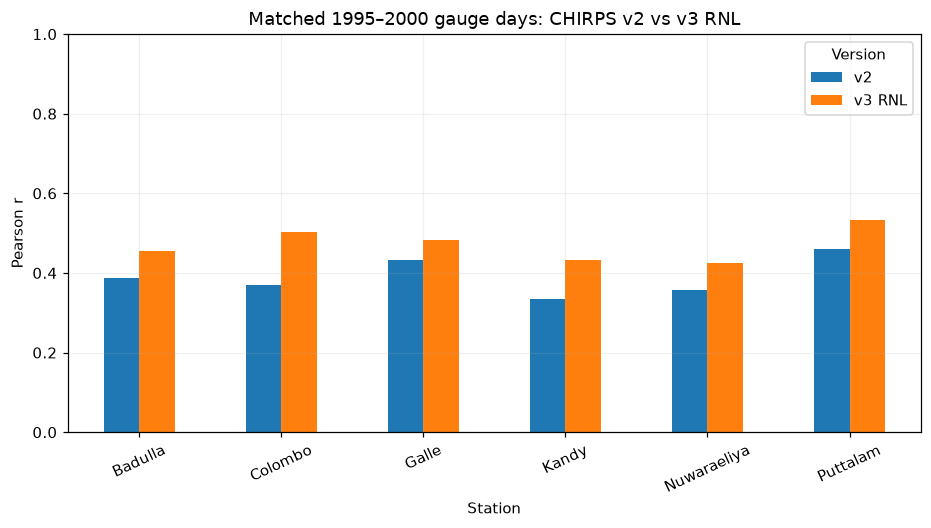

In [7]:
for metric,ylabel,tag in [('RMSE','Daily RMSE (mm/day)','product_daily_rmse'),
                           ('Pearson_r','Pearson r','product_daily_pearson')]:
    fig,ax=plt.subplots(figsize=(10,4.7))
    p=product_scores.pivot(index='Station',columns='Version',values=metric).reindex(stations)
    p.plot.bar(ax=ax,rot=25)
    ax.set_ylabel(ylabel);ax.set_xlabel('Station')
    ax.set_title('Matched 1995–2000 gauge days: CHIRPS v2 vs v3 RNL')
    if metric=='Pearson_r':ax.set_ylim(0,1)
    savefig(tag)


## 5 — Reproduce Notebook 17 validation-selected models
The simplest model within **1% of minimum validation RMSE** is selected on 1991–1994; model coefficients are fitted on 1981–1990, with the 1995–2000 test kept out of selection. This deliberately matches the original Notebook 17 design, not a new model search on test results.

In [9]:
def add_fourier(d):
    out=d.copy()
    phase=2*np.pi*(out.Date.dt.dayofyear.to_numpy()-1)/np.where(out.Date.dt.is_leap_year.to_numpy(),366.0,365.0)
    out['log1p_CHIRPS_v3']=np.log1p(out.CHIRPS_V3_mm)
    for nam,k,func in [('Sin1',1,np.sin),('Cos1',1,np.cos),('Sin2',2,np.sin),('Cos2',2,np.cos)]:
        out[nam]=func(k*phase)
    return out
train,valid,test=[add_fourier(z) for z in (train,valid,test)]
BASE=['log1p_CHIRPS_v3','Sin1','Cos1','Sin2','Cos2']
RAW='A: Raw CHIRPS v3'
FEATURE_SETS={
    'B: Seasonal Ridge':BASE,
    'C: + Moisture':BASE+['Specific_Humidity_gkg','RH_percent'],
    'D: + Wind':BASE+['Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms'],
    'E: + Local orography (exploratory)':BASE+['Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms','Orographic_Index','Upslope_w_ms']}
METHODS=[RAW]+list(FEATURE_SETS)
ALPHAS=[0.1,1.,10.,100.,1000.]
records=[];trained={}
for st in stations:
    tr=train[train.Station==st];va=valid[valid.Station==st]
    records.append(dict(Station=st,Method=RAW,Alpha=np.nan,**metrics(va.Rainfall_mm,va.CHIRPS_V3_mm)))
    for method,features in FEATURE_SETS.items():
        for alpha in ALPHAS:
            model=make_pipeline(StandardScaler(),Ridge(alpha=alpha))
            model.fit(tr[features],tr.Rainfall_mm)
            pred=np.maximum(0,model.predict(va[features]))
            records.append(dict(Station=st,Method=method,Alpha=alpha,**metrics(va.Rainfall_mm,pred)))
            trained[(st,method,alpha)]=model
validation_grid=pd.DataFrame(records)
validation_best=(validation_grid.sort_values(['Station','Method','RMSE','Alpha'],na_position='last')
                .groupby(['Station','Method'],as_index=False).first())
choices=[]
for st in stations:
    d=validation_best[validation_best.Station==st].copy()
    d['Complexity']=d.Method.map({v:i for i,v in enumerate(METHODS)})
    min_rmse=d.RMSE.min()
    chosen=d[d.RMSE<=1.01*min_rmse+1e-12].sort_values(['Complexity','RMSE']).iloc[0]
    choices.append(chosen)
station_choice=pd.DataFrame(choices).reset_index(drop=True)
display(station_choice[['Station','Method','Alpha','RMSE','Pearson_r']].round(3))


,Station,Method,Alpha,RMSE,Pearson_r
0,Badulla,C: + Moisture,0.1,10.021,0.436
1,Colombo,A: Raw CHIRPS v3,NaN,17.957,0.461
2,Galle,B: Seasonal Ridge,0.1,15.568,0.385
3,Kandy,C: + Moisture,10.0,9.516,0.480
4,Nuwaraeliya,D: + Wind,0.1,10.188,0.460
5,Puttalam,C: + Moisture,10.0,9.144,0.450


## 6 — Predictions for final test and model-performance tradeoffs

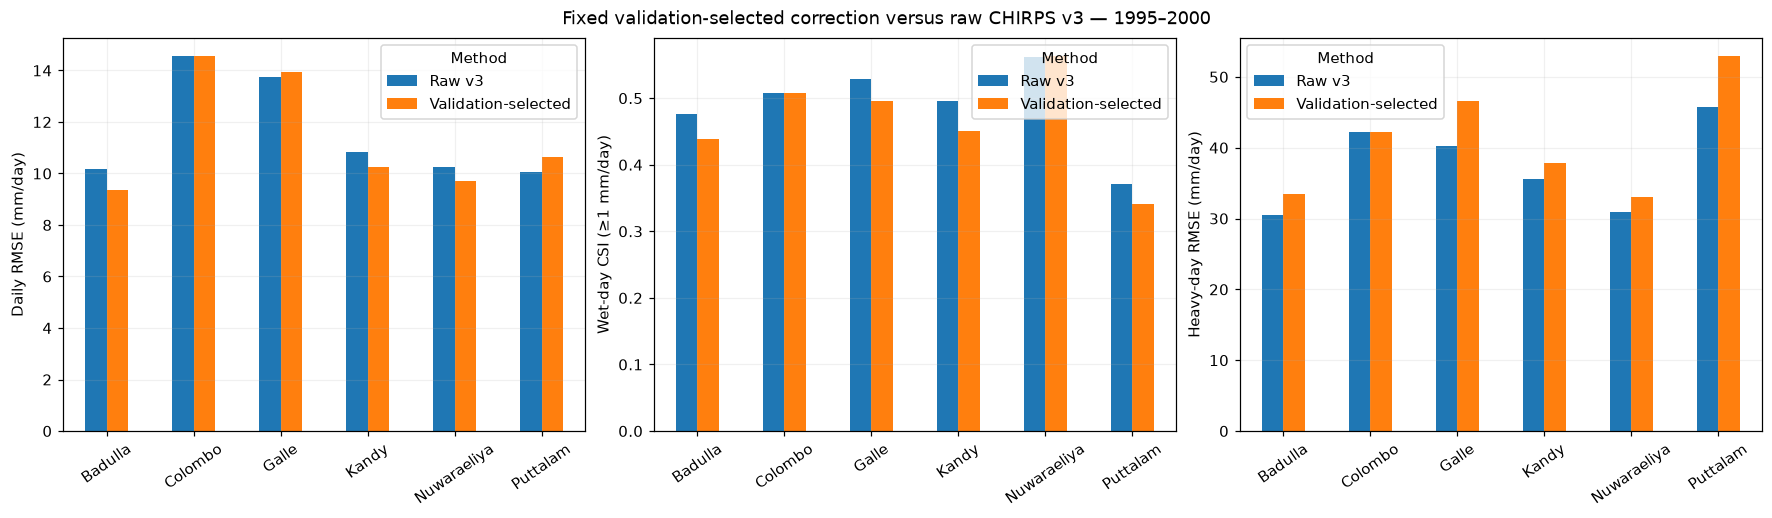

,Station,Method,N,Bias,MAE,RMSE,Pearson_r,Spearman_r
0,Badulla,Raw v3,2191,0.465,4.938,10.189,0.456,0.550
1,Badulla,Validation-selected,2191,0.408,5.012,9.363,0.463,0.607
2,Colombo,Raw v3,2191,0.483,7.203,14.543,0.503,0.562
3,Colombo,Validation-selected,2191,0.483,7.203,14.543,0.503,0.562
4,Galle,Raw v3,2192,-0.070,6.774,13.747,0.482,0.531
5,Galle,Validation-selected,2192,-0.614,6.924,13.931,0.412,0.512
6,Kandy,Raw v3,2190,0.180,5.361,10.829,0.433,0.531
7,Kandy,Validation-selected,2190,0.857,5.605,10.243,0.453,0.624
8,Nuwaraeliya,Raw v3,2180,-0.145,5.490,10.261,0.426,0.568
9,Nuwaraeliya,Validation-selected,2180,-0.256,5.335,9.697,0.447,0.608


In [11]:
p=[];model_rows=[];model_event=[];model_heavy=[]
for st in stations:
    t=test[test.Station==st].copy()
    sel=station_choice.loc[station_choice.Station==st].iloc[0]
    method=sel.Method
    t['Raw_v3_mm']=t.CHIRPS_V3_mm
    t['Selected_mm']=(t.Raw_v3_mm if method==RAW else
                      np.maximum(0,trained[(st,method,float(sel.Alpha))].predict(t[FEATURE_SETS[method]])))
    t['Selected_Method']=method
    p.append(t[['Date','Station','Rainfall_mm','Raw_v3_mm','Selected_mm','Selected_Method']])
    for label,col in [('Raw v3','Raw_v3_mm'),('Validation-selected','Selected_mm')]:
        model_rows.append(dict(Station=st,Method=label,**metrics(t.Rainfall_mm,t[col])))
        model_event.append(dict(Station=st,Method=label,**wet(t.Rainfall_mm,t[col])))
        h=t[t.Rainfall_mm>25]
        model_heavy.append(dict(Station=st,Method=label,**metrics(h.Rainfall_mm,h[col])))
final_preds=pd.concat(p,ignore_index=True)
model_scores=pd.DataFrame(model_rows)
model_wet=pd.DataFrame(model_event)
model_heavy=pd.DataFrame(model_heavy)
fig,axes=plt.subplots(1,3,figsize=(16,4.6),constrained_layout=True)
for ax,frame,metric,label in [
 (axes[0],model_scores,'RMSE','Daily RMSE (mm/day)'),
 (axes[1],model_wet,'CSI','Wet-day CSI (≥1 mm/day)'),
 (axes[2],model_heavy,'RMSE','Heavy-day RMSE (mm/day)')]:
    pivot=frame.pivot(index='Station',columns='Method',values=metric).reindex(stations)
    pivot.plot.bar(ax=ax,rot=35)
    ax.set_xlabel('');ax.set_ylabel(label)
fig.suptitle('Fixed validation-selected correction versus raw CHIRPS v3 — 1995–2000')
savefig('selected_model_daily_wet_heavy_tradeoffs')
display(model_scores.round(3))


## 7 — Atmospheric correlation matrices: Pearson and Spearman

Use development years **1981–1994** for descriptive feature exploration. Skewed/zero-inflated rain can make Pearson and Spearman differ. These are associations, not causal effects and not model performance. Avoid using full-series `V3_Error` as a predictor (it depends on the ground truth).

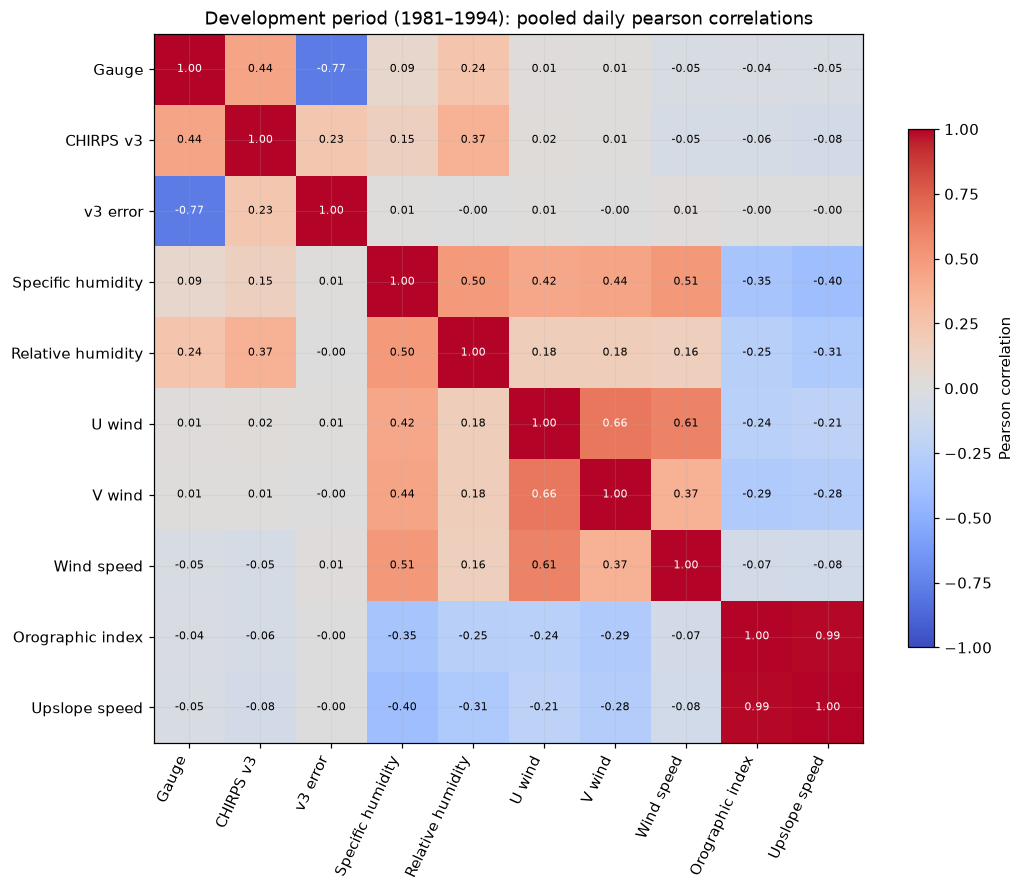

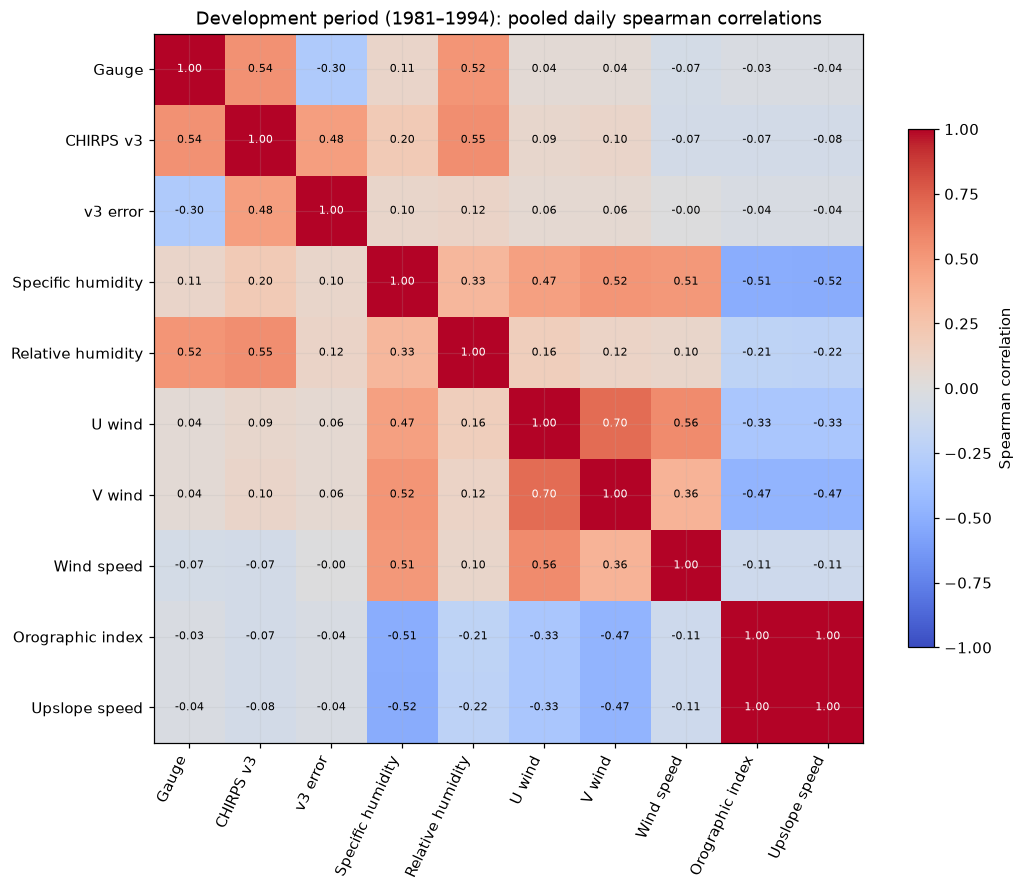

In [13]:
dev=df.loc[df.Date.between('1981-01-01','1994-12-31')].copy()
dev['V3_Error_mm']=dev.CHIRPS_V3_mm-dev.Rainfall_mm
feature_cols=['Rainfall_mm','CHIRPS_V3_mm','V3_Error_mm','Specific_Humidity_gkg',
              'RH_percent','U10_ms','V10_ms','Wind_Speed_ms',
              'Orographic_Index','Upslope_w_ms']
labels={'Rainfall_mm':'Gauge','CHIRPS_V3_mm':'CHIRPS v3','V3_Error_mm':'v3 error',
        'Specific_Humidity_gkg':'Specific humidity','RH_percent':'Relative humidity',
        'U10_ms':'U wind','V10_ms':'V wind','Wind_Speed_ms':'Wind speed',
        'Orographic_Index':'Orographic index','Upslope_w_ms':'Upslope speed'}
for kind in ['pearson','spearman']:
    correlation=dev[feature_cols].corr(method=kind)
    correlation.to_csv(OUT/f'pooled_daily_{kind}_correlation.csv')
    fig,ax=plt.subplots(figsize=(10.4,8.5))
    img=ax.imshow(correlation,vmin=-1,vmax=1,cmap='coolwarm',aspect='equal')
    ax.set_xticks(range(len(feature_cols)),[labels[f] for f in feature_cols],rotation=65,ha='right')
    ax.set_yticks(range(len(feature_cols)),[labels[f] for f in feature_cols])
    for i in range(len(feature_cols)):
        for j in range(len(feature_cols)):
            ax.text(j,i,f'{correlation.iloc[i,j]:.2f}',ha='center',va='center',fontsize=7,
                    color='white' if abs(correlation.iloc[i,j])>.65 else 'black')
    fig.colorbar(img,ax=ax,shrink=.72,label=kind.title()+' correlation')
    ax.set_title(f'Development period (1981–1994): pooled daily {kind} correlations')
    savefig(f'pooled_{kind}_atmospheric_heatmap')


## 8 — Correlation patterns differ by station
Show Kandy, Nuwara Eliya and Colombo separately, avoiding the assumption that all sites share the same atmospheric response. These plots are descriptive; correlated time samples are not spatially independent.

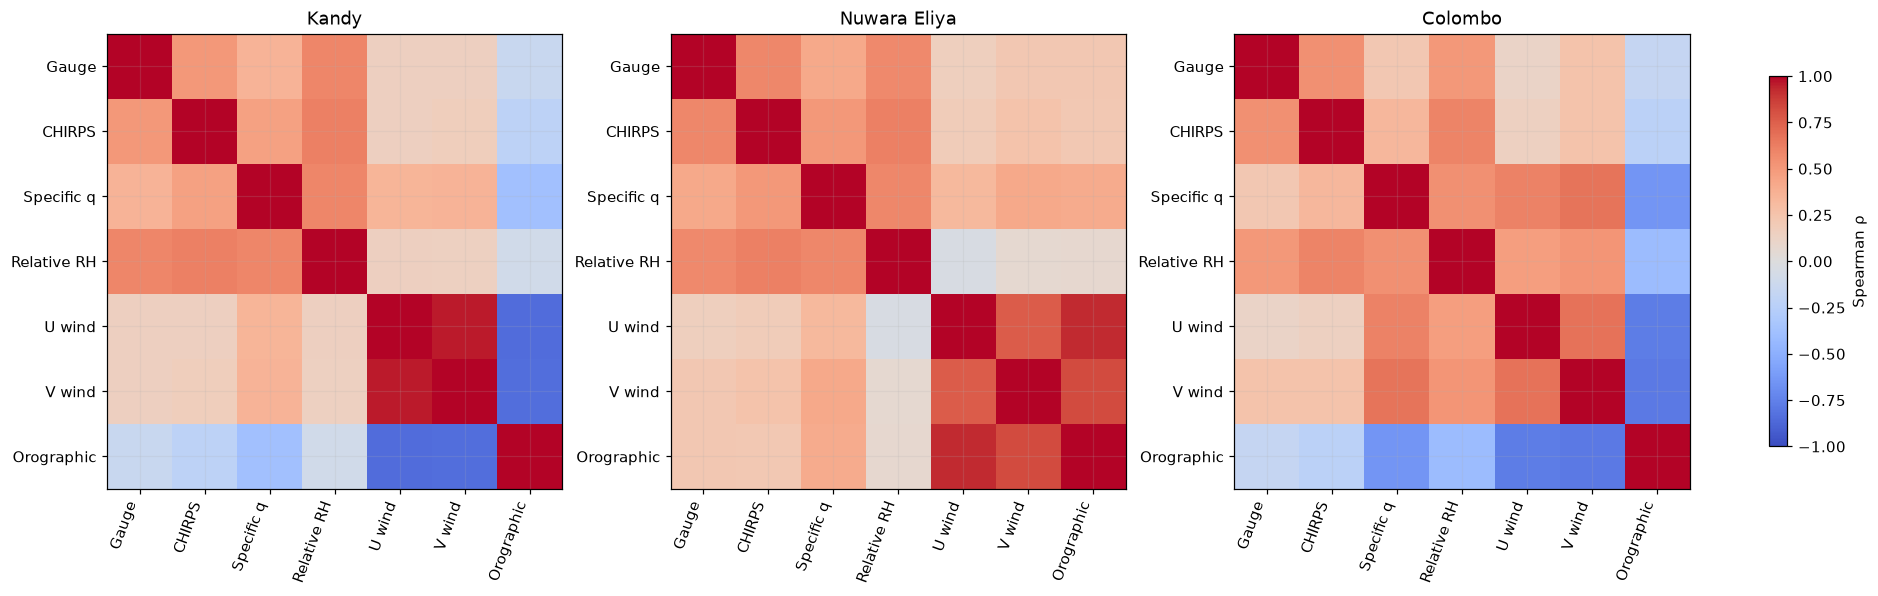

In [15]:
selected_stations=['Kandy','Nuwaraeliya','Colombo']
subset=['Rainfall_mm','CHIRPS_V3_mm','Specific_Humidity_gkg','RH_percent',
        'U10_ms','V10_ms','Orographic_Index']
fig,axes=plt.subplots(1,3,figsize=(17,5.7),constrained_layout=True)
for ax,st in zip(axes,selected_stations):
    mat=dev.loc[dev.Station==st,subset].corr(method='spearman')
    mat.to_csv(OUT/f'{st}_spearman_correlation.csv')
    im=ax.imshow(mat,vmin=-1,vmax=1,cmap='coolwarm')
    short=['Gauge','CHIRPS','Specific q','Relative RH','U wind','V wind','Orographic']
    ax.set_xticks(range(len(short)),short,rotation=70,ha='right')
    ax.set_yticks(range(len(short)),short)
    ax.set_title(st.replace('Nuwaraeliya','Nuwara Eliya'))
fig.colorbar(im,ax=axes.tolist(),shrink=.65,label='Spearman ρ')
savefig('station_specific_spearman_Kandy_NuwaraEliya_Colombo')


## 9 — Terrain versus station-level satellite errors
**Exactly six points**, one per station. Repeated daily terrain rows do not constitute thousands of independent terrain observations. Terrain plots are exploratory only. Point elevation is not a rain-shadow measurement. This original dataset includes earlier local surface gradients; corrected-gradient conclusions require your later file.

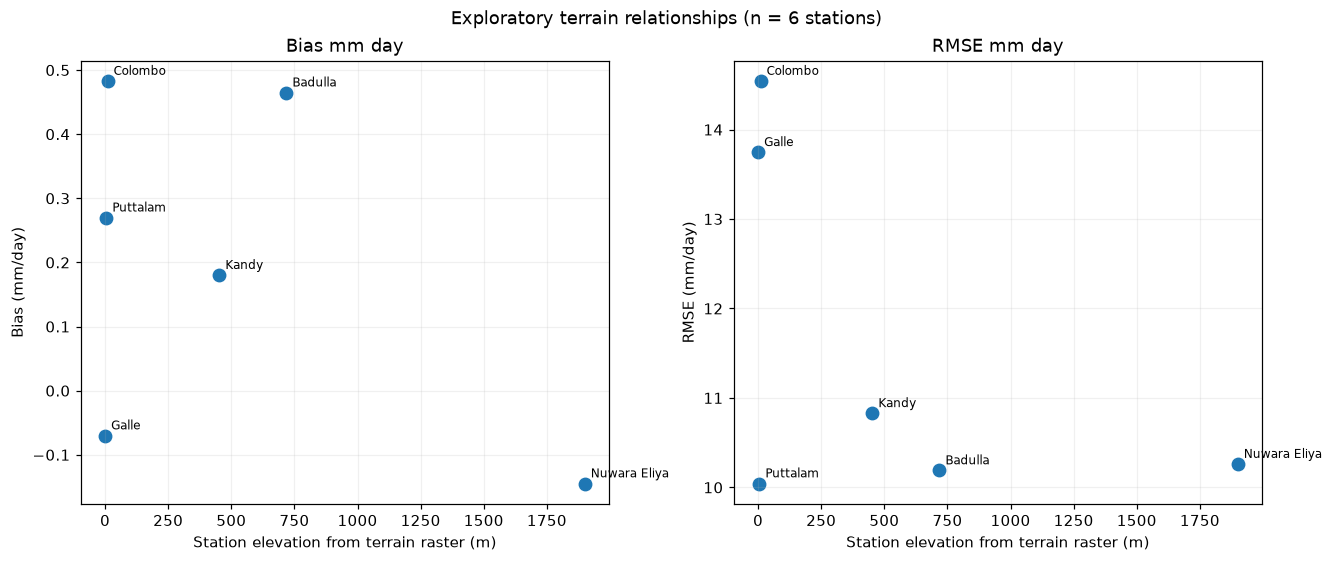

In [17]:
terrain_fields=[c for c in ['Elevation_m','Slope_deg','Aspect_deg'] if c in df]
error_stats=test.assign(v3_error=test.CHIRPS_V3_mm-test.Rainfall_mm).groupby('Station').agg(
    Bias_mm_day=('v3_error','mean'),MAE_mm_day=('v3_error',lambda x:np.abs(x).mean()),
    RMSE_mm_day=('v3_error',lambda x:np.sqrt(np.mean(x*x))))
terrain=df.groupby('Station')[terrain_fields].first().join(error_stats).reset_index()
terrain.to_csv(OUT/'station_terrain_vs_raw_error.csv',index=False)
if 'Elevation_m' in terrain:
    fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
    for ax,y in zip(axes,['Bias_mm_day','RMSE_mm_day']):
        ax.scatter(terrain.Elevation_m,terrain[y],s=65)
        for _,r in terrain.iterrows():
            ax.annotate(r.Station.replace('Nuwaraeliya','Nuwara Eliya'),
                        (r.Elevation_m,r[y]),xytext=(4,4),textcoords='offset points',fontsize=8)
        ax.set_xlabel('Station elevation from terrain raster (m)')
        ax.set_ylabel(('Bias (mm/day)' if y.startswith('Bias') else 'RMSE (mm/day)'))
        ax.set_title(y.replace('_',' '))
    fig.suptitle('Exploratory terrain relationships (n = 6 stations)')
    savefig('station_elevation_vs_raw_v3_error')
else:print('Elevation_m not found; terrain plot skipped')


## 10 — Complete-month climatology and normalized cumulative rainfall
Only full months with complete matched gauge and satellite observations. The climatology is the average monthly **total** (mm/month). Normalized cumulative annual rainfall is compared within each complete year so differences in annual totals do not masquerade as seasonal-timing differences.

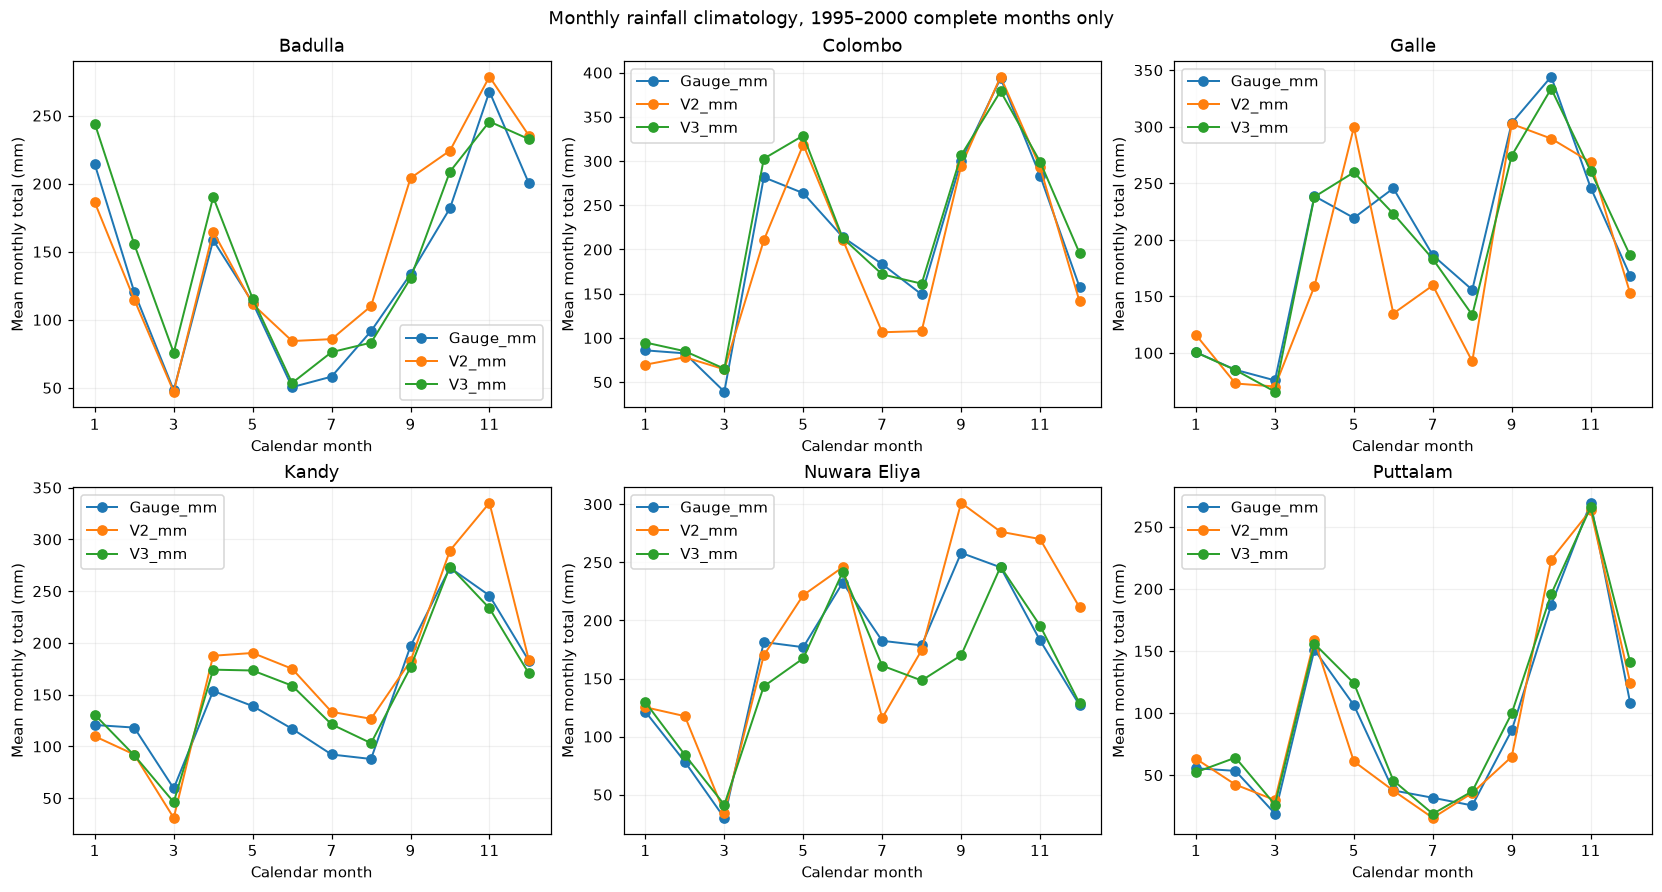

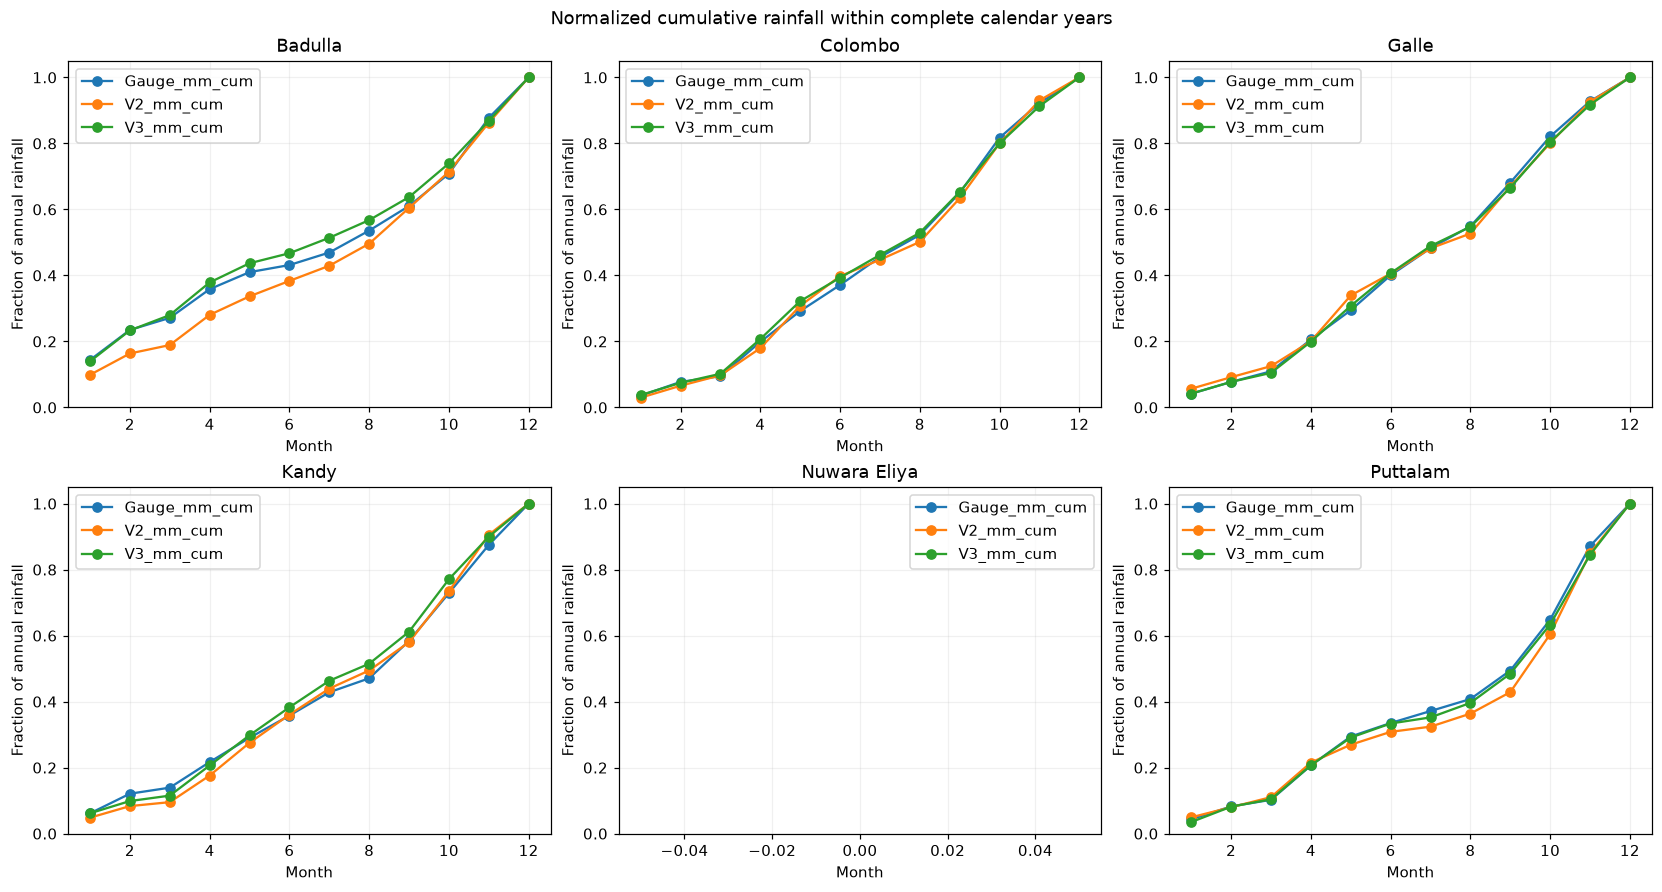

Complete calendar-year station groups: 24


In [19]:
d=test.copy()
d['Month']=d.Date.dt.to_period('M')
monthly=d.groupby(['Station','Month'],as_index=False).agg(
    Days=('Date','nunique'),Gauge_mm=('Rainfall_mm','sum'),V2_mm=('CHIRPS_mm','sum'),V3_mm=('CHIRPS_V3_mm','sum'))
monthly['Expected']=monthly.Month.dt.days_in_month
monthly=monthly[monthly.Days==monthly.Expected].copy()
monthly['Year']=monthly.Month.dt.year
monthly['CalendarMonth']=monthly.Month.dt.month
monthly.to_csv(OUT/'complete_month_totals.csv',index=False)
fig,axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
for ax,st in zip(axes.flat,stations):
    d=monthly[monthly.Station==st]
    clim=d.groupby('CalendarMonth')[['Gauge_mm','V2_mm','V3_mm']].mean()
    clim.plot(ax=ax,marker='o',lw=1.3)
    ax.set_title(st.replace('Nuwaraeliya','Nuwara Eliya'))
    ax.set_xlabel('Calendar month');ax.set_ylabel('Mean monthly total (mm)')
    ax.set_xticks([1,3,5,7,9,11])
fig.suptitle('Monthly rainfall climatology, 1995–2000 complete months only')
savefig('complete_month_climatology')
# Require all 12 months per station/year (no missing-month renormalization)
full=monthly.groupby(['Station','Year']).filter(lambda z:len(z)==12).copy()
for col in ['Gauge_mm','V2_mm','V3_mm']:
    full[col+'_fraction']=full[col]/full.groupby(['Station','Year'])[col].transform('sum').replace(0,np.nan)
    full[col+'_cum']=full.sort_values('CalendarMonth').groupby(['Station','Year'])[col+'_fraction'].cumsum()
fig,axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
for ax,st in zip(axes.flat,stations):
    z=full[full.Station==st].groupby('CalendarMonth')[[k+'_cum' for k in ['Gauge_mm','V2_mm','V3_mm']]].mean()
    z.plot(ax=ax,marker='o')
    ax.set_title(st.replace('Nuwaraeliya','Nuwara Eliya'))
    ax.set_ylim(0,1.05);ax.set_xlabel('Month');ax.set_ylabel('Fraction of annual rainfall')
fig.suptitle('Normalized cumulative rainfall within complete calendar years')
savefig('normalized_cumulative_rainfall')
print('Complete calendar-year station groups:',full.groupby(['Station','Year']).ngroups)


## 11 — Final report scatter plots (gauge versus raw v3 versus selected correction)

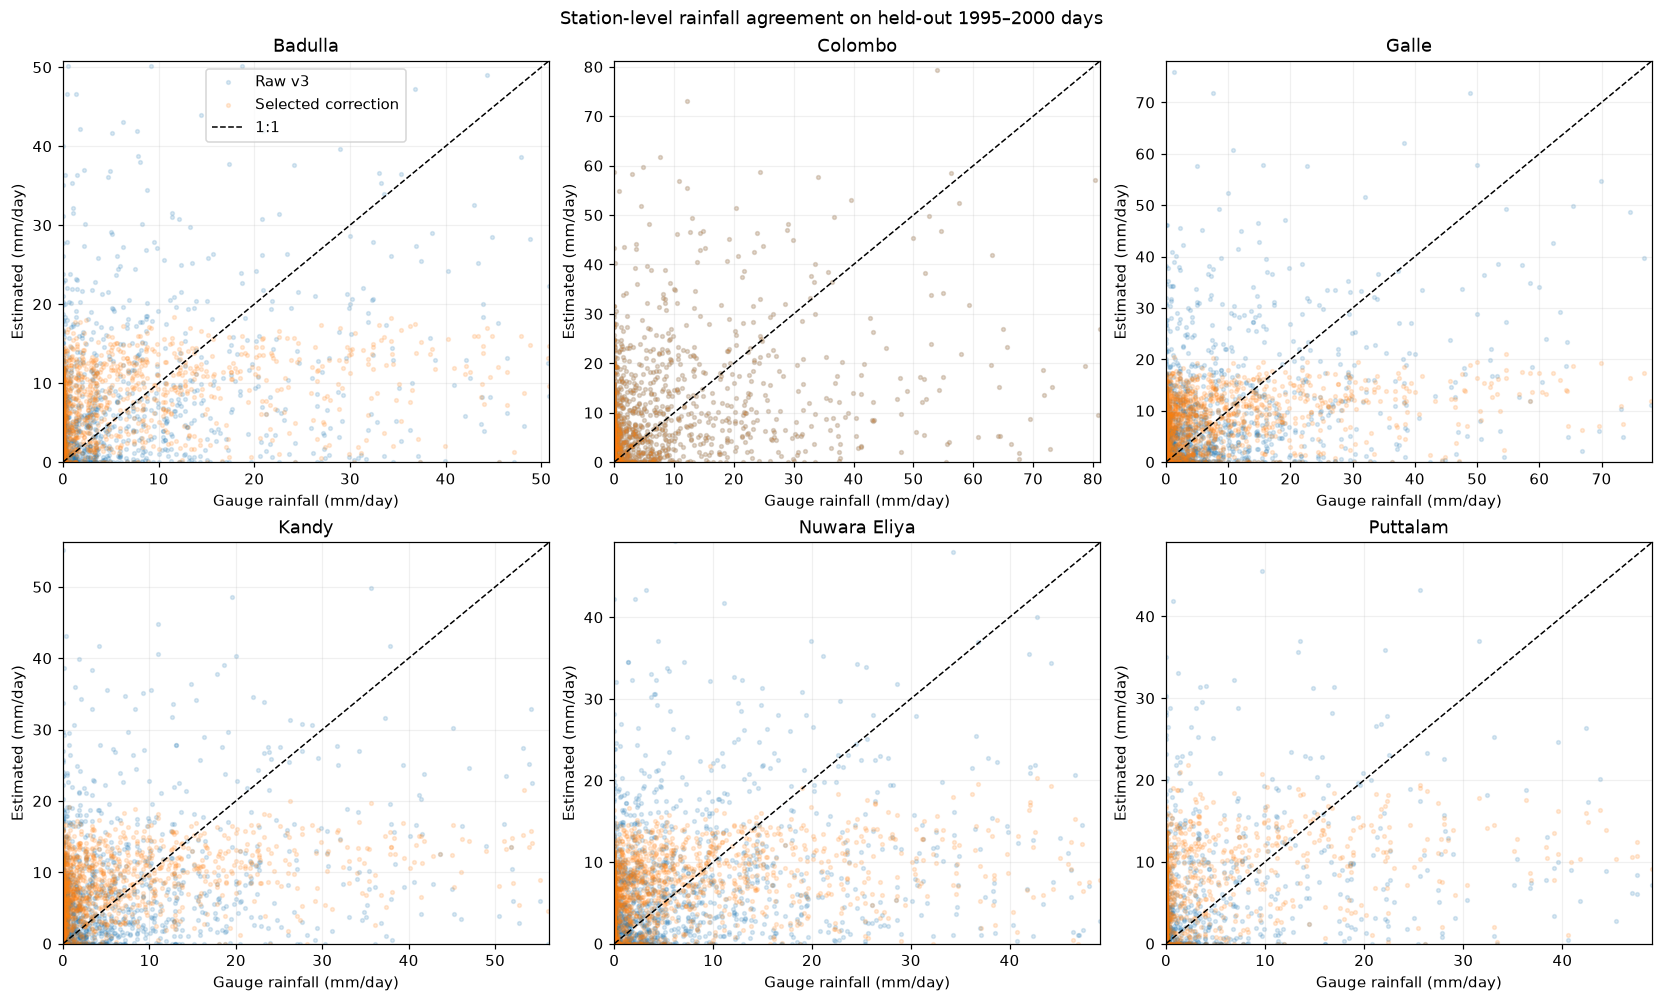

In [20]:
fig,axes=plt.subplots(2,3,figsize=(15,9),constrained_layout=True)
for ax,st in zip(axes.flat,stations):
    d=final_preds[final_preds.Station==st]
    ax.scatter(d.Rainfall_mm,d.Raw_v3_mm,s=6,alpha=.16,label='Raw v3')
    ax.scatter(d.Rainfall_mm,d.Selected_mm,s=6,alpha=.16,label='Selected correction')
    lim=float(d[['Rainfall_mm','Raw_v3_mm','Selected_mm']].quantile(.99).max())
    lim=max(lim,1)
    ax.plot([0,lim],[0,lim],'k--',lw=1,label='1:1')
    ax.set_xlim(0,lim);ax.set_ylim(0,lim)
    ax.set_title(st.replace('Nuwaraeliya','Nuwara Eliya'))
    ax.set_xlabel('Gauge rainfall (mm/day)');ax.set_ylabel('Estimated (mm/day)')
axes[0,0].legend()
fig.suptitle('Station-level rainfall agreement on held-out 1995–2000 days')
savefig('raw_vs_selected_scatter_all_stations')


## 12 — Optional: spatial-buffer & temporal-scale comparison
This section runs only if all **40 yearly exports** are present in `data/chirps/buffered/`; otherwise the rest of the notebook is complete and it prints a useful message. Matched gauge days and complete temporal periods are required.

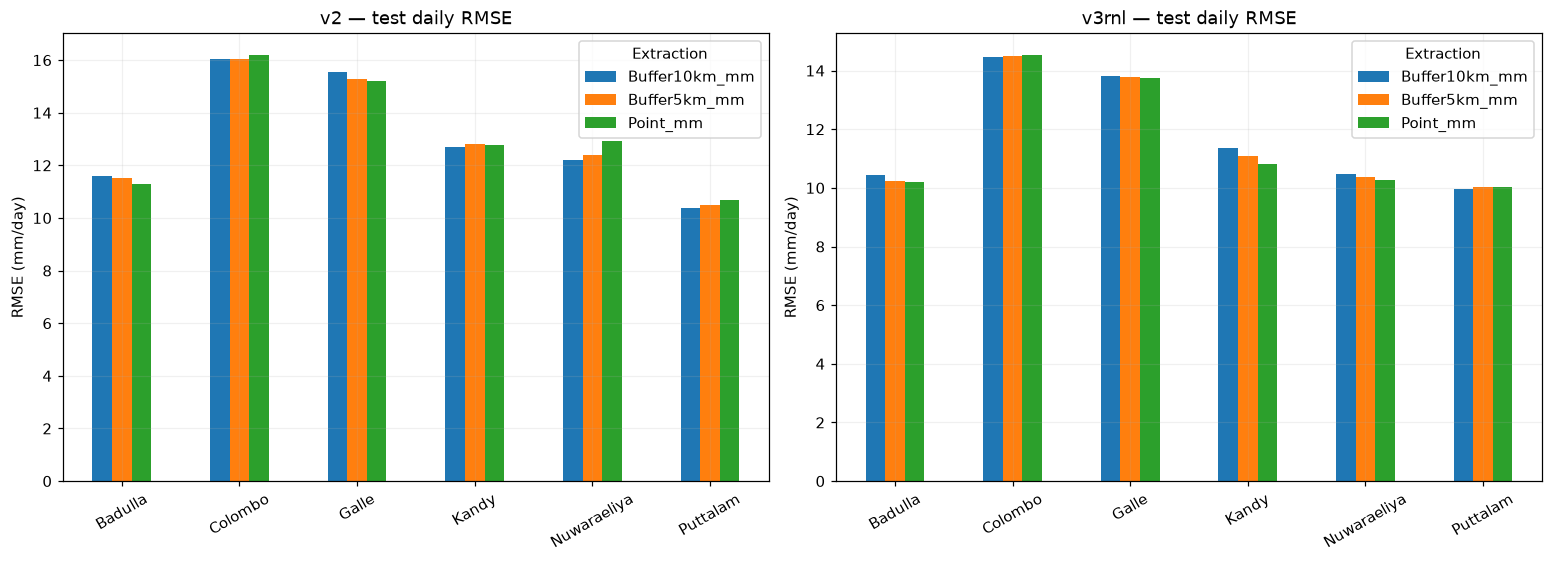

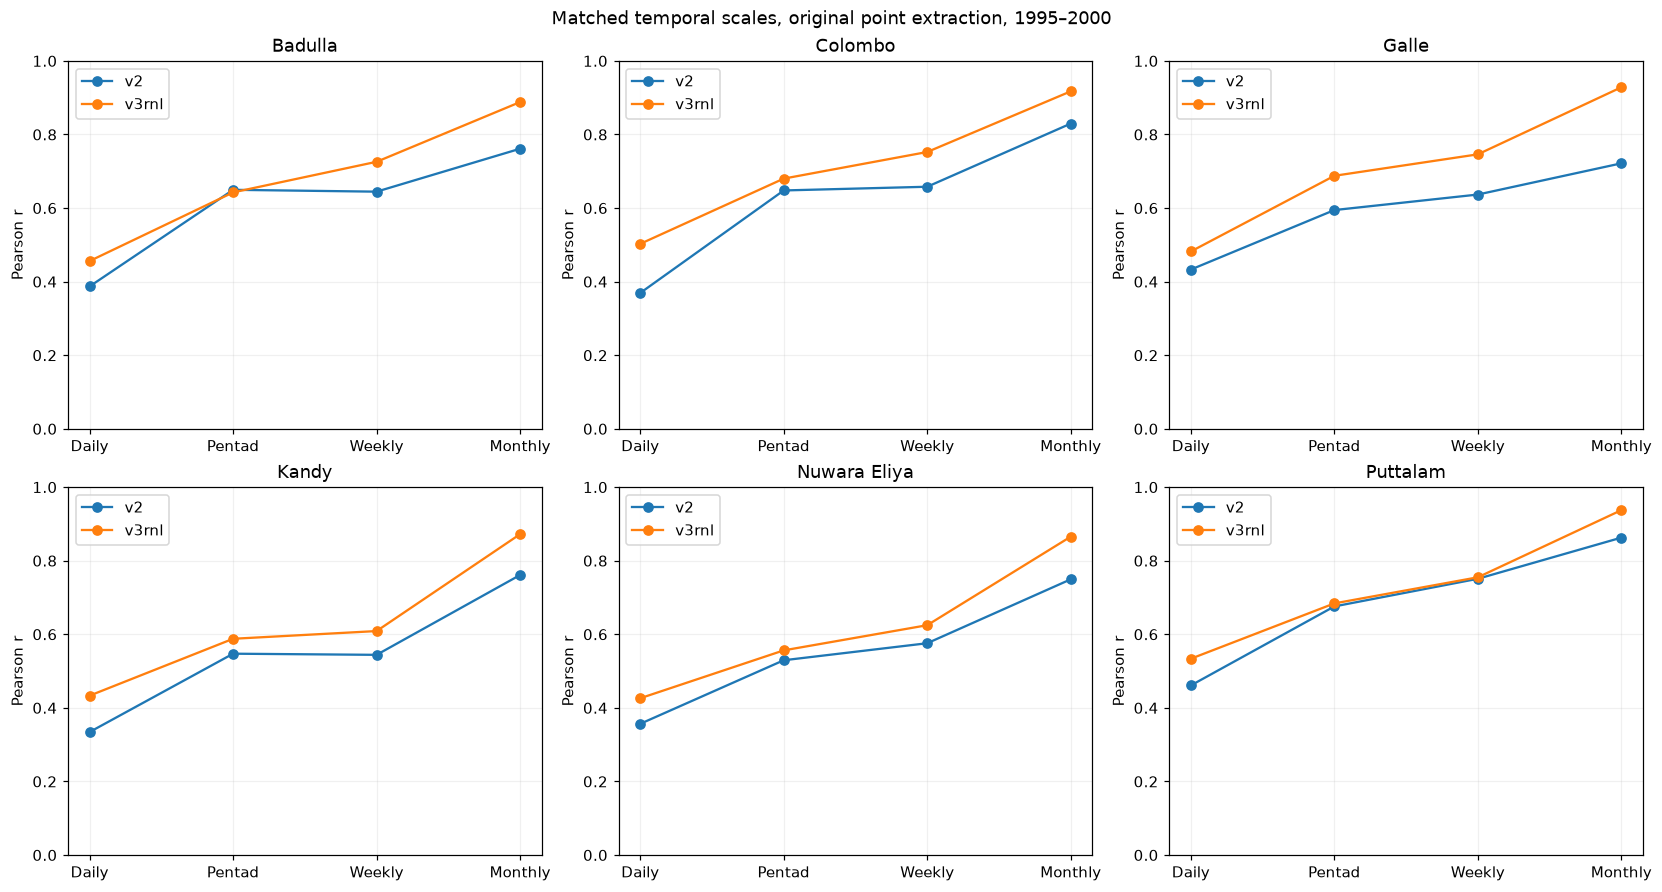

In [21]:
from scipy.stats import spearmanr
cols=['Point_mm','Buffer5km_mm','Buffer10km_mm']
def load_buffer(version):
    fs=sorted(BUFFER_DIR.glob(f'CHIRPS_Buffer_{version}_*.csv'))
    years={str(y) for y in range(1981,2001)}
    found={p.stem.split('_')[-1] for p in fs}
    if len(fs)!=20 or found!=years:
        print(f'{version}: found {len(fs)}/20 CSVs; optional buffered graphics skipped.')
        return None
    z=pd.concat([pd.read_csv(p,usecols=['Date','Station']+cols) for p in fs],ignore_index=True)
    z['Date']=pd.to_datetime(z.Date)
    z['Station']=z.Station.astype(str).str.strip().replace({'Nuwara Eliya':'Nuwaraeliya'})
    assert not z.duplicated(['Station','Date']).any(), f'Duplicate {version} station-date rows'
    return z.rename(columns={k:f'{version}_{k}' for k in cols})
b2=load_buffer('v2');b3=load_buffer('v3rnl')
if b2 is not None and b3 is not None:
    # test gauge is guaranteed valid and common through join
    common=test[['Station','Date','Rainfall_mm']].merge(b2,on=['Station','Date'],validate='one_to_one').merge(
        b3,on=['Station','Date'],validate='one_to_one')
    variables=[f'{v}_{c}' for v in ['v2','v3rnl'] for c in cols]
    common[variables]=common[variables].apply(pd.to_numeric,errors='coerce')
    common=common.dropna(subset=variables)
    br=[]
    for st,d in common.groupby('Station'):
        for ver in ['v2','v3rnl']:
            for radius in cols:
                br.append(dict(Station=st,Version=ver,Extraction=radius,
                               **metrics(d.Rainfall_mm,d[f'{ver}_{radius}'])))
    buffer_scores=pd.DataFrame(br)
    buffer_scores.to_csv(OUT/'buffer_daily_scores_on_common_days.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
    for ax,ver in zip(axes,['v2','v3rnl']):
        q=buffer_scores[buffer_scores.Version==ver].pivot(index='Station',columns='Extraction',values='RMSE').reindex(stations)
        q.plot.bar(ax=ax,rot=30)
        ax.set_title(ver+' — test daily RMSE');ax.set_ylabel('RMSE (mm/day)');ax.set_xlabel('')
    savefig('buffered_point_5km_10km_daily_rmse')
    def complete_periods(d,kind):
        q=d.copy()
        if kind=='pentad':
            block=np.minimum((q.Date.dt.day-1)//5,5)
            q['Period']=q.Date.dt.to_period('M').dt.start_time+pd.to_timedelta(block*5,unit='D')
            q['Expected']=np.where(block.eq(5),q.Date.dt.days_in_month-25,5)
        elif kind=='weekly':
            q['Period']=q.Date-pd.to_timedelta(q.Date.dt.dayofweek,unit='D');q['Expected']=7
        else:
            q['Period']=q.Date.dt.to_period('M').dt.start_time;q['Expected']=q.Date.dt.days_in_month
        agg={c:(c,'sum') for c in ['Rainfall_mm']+variables}
        agg.update({'Days':('Date','nunique'),'Expected':('Expected','first')})
        zz=q.groupby(['Station','Period'],as_index=False).agg(**agg)
        return zz[zz.Days==zz.Expected]
    acc=[]
    for st,d in common.groupby('Station'):
        for ver in ['v2','v3rnl']:
            acc.append(dict(Station=st,Version=ver,Scale='Daily',
                            **metrics(d.Rainfall_mm,d[f'{ver}_Point_mm'])))
    for scale in ['pentad','weekly','monthly']:
        agg=complete_periods(common,scale)
        for st,d in agg.groupby('Station'):
            for ver in ['v2','v3rnl']:
                acc.append(dict(Station=st,Version=ver,Scale=scale.title(),
                                **metrics(d.Rainfall_mm,d[f'{ver}_Point_mm'])))
    temporal_scores=pd.DataFrame(acc)
    temporal_scores.to_csv(OUT/'matched_temporal_correlations.csv',index=False)
    fig,axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
    for ax,st in zip(axes.flat,stations):
        for ver in ['v2','v3rnl']:
            z=temporal_scores[(temporal_scores.Station==st)&(temporal_scores.Version==ver)]
            vals=z.set_index('Scale').reindex(['Daily','Pentad','Weekly','Monthly'])
            ax.plot(vals.index,vals.Pearson_r,marker='o',label=ver)
        ax.set_title(st.replace('Nuwaraeliya','Nuwara Eliya'))
        ax.set_ylim(0,1);ax.set_ylabel('Pearson r');ax.legend()
    fig.suptitle('Matched temporal scales, original point extraction, 1995–2000')
    savefig('daily_pentad_weekly_monthly_correlations')
else:
    print('Optional buffered/temporal plots skipped; other figures and tables are complete.')


## 13 — Save final reusable data tables and figure inventory

In [24]:
table_data={
    'product_daily_scores':product_scores,
    'product_wetday_scores':product_wet,
    'product_heavyday_scores':product_heavy,
    'station_model_choices_validation':station_choice,
    'station_model_daily_scores':model_scores,
    'station_model_wetday_scores':model_wet,
    'station_model_heavyday_scores':model_heavy,
    'station_model_test_predictions':final_preds}
for name,z in table_data.items():z.to_csv(OUT/f'{name}.csv',index=False)
print('Saved tables:',len(list(OUT.glob('*.csv'))))
print('Saved report-ready figures (PNG):',len(list(OUT.glob('*.png'))))
print('Saved vector figures (PDF):',len(list(OUT.glob('*.pdf'))))
print('Results directory:',OUT.resolve())
print('DO NOT interpret pooled or six-station correlations as causal evidence.')


Saved tables: 17
Saved report-ready figures (PNG): 12
Saved vector figures (PDF): 12
Results directory: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\18_Final_Visualizations\run_001
DO NOT interpret pooled or six-station correlations as causal evidence.


## Interpretation & reporting checklist

- **Products:** v3 RNL usually has better daily overall statistics than v2 at the six stations; report exceptions by metric and station. Use matched dates.
- **Aggregation:** stronger correlations for accumulated totals are not proof that pentad redistribution is the only cause.
- **Buffer:** spatial averaging can reduce representativeness mismatch but smooth localized extremes; choose radius on development data, not test data.
- **Physics:** the current earlier DEM gradients are exploratory; moisture/wind effects are not proof of orographic causation. Model selection occurred before testing, and some calibrated models worsen heavy-rainfall and monthly results.
- **Climatology:** complete-month and complete-year restrictions are stated in the plot captions.
- **Submission:** show a small selection of these figures in the presentation; retain the remainder as supplementary figures for the report and viva.
